# Глубокий анализ признаков и статистические гипотезы

## Импорты

In [21]:
from pathlib import Path

In [22]:
from sklearn.preprocessing import LabelEncoder
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

In [23]:
from src.dataset import DatasetStore

In [24]:
import warnings
warnings.filterwarnings('ignore')

## Загрузка данных

In [25]:
df, schema = DatasetStore.load(
    "data/processed/dataset.csv",
    "data/processed/dataset.schema.json",
    include_missing=False,
)
feature_info = DatasetStore.get_feature_info(
    schema,
    include_missing=False,
)
target = "diagnosis"

y = LabelEncoder().fit_transform(df[target].values)
X = df.drop(columns=[target])

class_labels = [0, 1]

In [ ]:
RESULTS_PATH = Path('reports/feature_target_associations.csv')
if RESULTS_PATH.exists():
    results_df = pd.read_csv(RESULTS_PATH)
else:
    raise FileNotFoundError('Сначала запустите 02_eda.ipynb, чтобы создать reports/feature_target_associations.csv')
results_df.head()

,feature,chi2,p_value,dof,cramers_v
0,meteorism,141.459236,1.916537e-31,2,0.597212
1,LS/cen gid,220.443965,3.102614e-43,8,0.521863
2,rigid of abdomi,197.185508,2.502506e-38,8,0.492466
3,Ur,85.574244,2.616912e-19,2,0.462313
4,LS steat,140.678448,2.020187e-29,4,0.418590


## 1. Ассоциации между признаками

In [27]:
from itertools import combinations

def cramers_v(x, y):
    ct = pd.crosstab(x, y)
    if ct.shape[0] < 2 or ct.shape[1] < 2:
        return np.nan
    chi2 = stats.chi2_contingency(ct, correction=False)[0]   # ← без Yates
    n = ct.values.sum()
    r, k = ct.shape
    phi2 = chi2 / n
    phi2c = max(0.0, phi2 - (k - 1) * (r - 1) / (n - 1))
    rc = r - (r - 1) ** 2 / (n - 1)
    kc = k - (k - 1) ** 2 / (n - 1)
    return float(np.sqrt(phi2c / min(kc - 1, rc - 1)))

def cramers_v_matrix(df, cols):
    m = pd.DataFrame(np.eye(len(cols)), index=cols, columns=cols)
    for a, b in combinations(cols, 2):
        m.loc[a, b] = m.loc[b, a] = cramers_v(df[a], df[b])
    return m

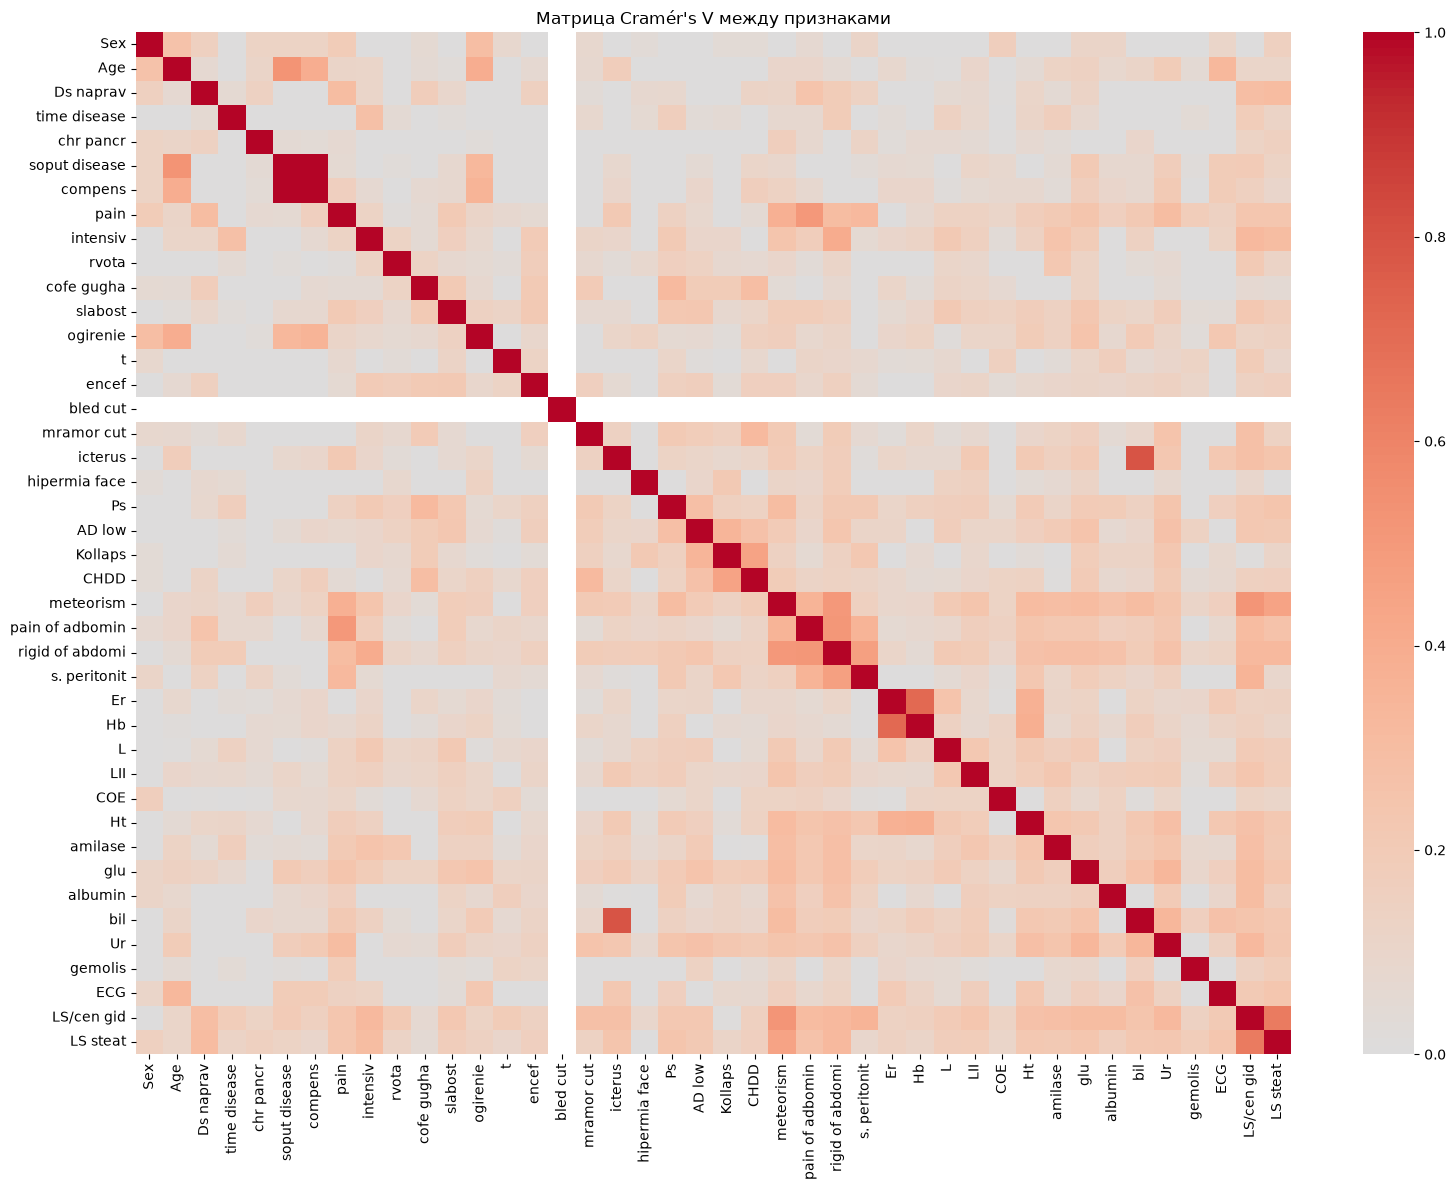

In [28]:
feature_cols = [c for c in df.columns if c != target]
assoc_matrix = cramers_v_matrix(df, feature_cols)

plt.figure(figsize=(16, 12))
sns.heatmap(assoc_matrix, cmap='coolwarm', center=0, vmin=0, vmax=1)
plt.title('Матрица Cramér\'s V между признаками')
plt.tight_layout()
plt.show()

In [29]:
pairs = []
for i in range(len(feature_cols)):
    for j in range(i+1, len(feature_cols)):
        v = assoc_matrix.iloc[i, j]
        if pd.notna(v) and v > 0.7:
            pairs.append({'feature_1': feature_cols[i], 'feature_2': feature_cols[j], 'cramers_v': v})
pairs_df = pd.DataFrame(pairs).sort_values('cramers_v', ascending=False)
display(pairs_df)
print(f'Пар с V > 0.7: {len(pairs_df)}')

,feature_1,feature_2,cramers_v
0,soput disease,compens,0.998717
1,icterus,bil,0.795578
2,Er,Hb,0.715449


Пар с V > 0.7: 3


## 2. Распределение признаков

In [30]:
categorical_cols = [col for col in df.columns if isinstance(df[col].dtype, pd.CategoricalDtype) and col != target]
for col in categorical_cols:
    print(f'\n=== {col} vs {target} ===')

    print(f'-- Доли по строкам (нормировка по {col}, сумма по строкам = 1) --')
    ct_rows = pd.crosstab(df[col], df[target], normalize='index').round(3)
    display(ct_rows)

    print(f'-- Доли по столбцам (нормировка по {target}, сумма по столбцам = 1) --')
    ct_cols = pd.crosstab(df[col], df[target], normalize='columns').round(3)
    display(ct_cols)


=== Sex vs diagnosis ===
-- Доли по строкам (нормировка по Sex, сумма по строкам = 1) --


diagnosis,1,5,6
Sex,,,
муж,0.642,0.194,0.164
жен,0.562,0.256,0.181


-- Доли по столбцам (нормировка по diagnosis, сумма по столбцам = 1) --


diagnosis,1,5,6
Sex,,,
муж,0.623,0.523,0.567
жен,0.377,0.477,0.433



=== Age vs diagnosis ===
-- Доли по строкам (нормировка по Age, сумма по строкам = 1) --


...

diagnosis,1,5,6
LS/cen gid,,,
не делали,0.904,0.302,0.134
нет выпота,0.050,0.047,0.030
серозный,0.038,0.163,0.224
геморрагический,0.008,0.477,0.567
гнойный,0.000,0.012,0.045



=== LS steat vs diagnosis ===
-- Доли по строкам (нормировка по LS steat, сумма по строкам = 1) --


diagnosis,1,5,6
LS steat,,,
не делали,0.786,0.123,0.091
нет,0.355,0.403,0.242
есть,0.000,0.500,0.500


-- Доли по столбцам (нормировка по diagnosis, сумма по столбцам = 1) --


diagnosis,1,5,6
LS steat,,,
не делали,0.908,0.395,0.373
нет,0.092,0.291,0.224
есть,0.000,0.314,0.403


## 3. Вклад категориальных признаков в целевую переменную

In [31]:
categorical_cols = [col for col in df.columns if isinstance(df[col].dtype, pd.CategoricalDtype) and col != target]

target_values = sorted(df[target].dropna().unique())
target_props = df[target].value_counts(normalize=True).reindex(target_values)

rows = []
for col in categorical_cols:
    ct = pd.crosstab(df[col], df[target])
    if ct.shape[0] < 2 or ct.shape[1] < 2:
        row = {'feature': col, 'p_value': np.nan, 'chi2': np.nan}
        row.update({f'{target}_{t}_prop_diff': np.nan for t in target_values})
        rows.append(row)
        continue

    chi2, p, _, _ = stats.chi2_contingency(ct, correction=False)

    # P(target=t | level) для каждого уровня признака
    level_props = ct.div(ct.sum(axis=1), axis=0)
    # отклонение от базовой доли таргета
    diffs = level_props.sub(target_props.reindex(level_props.columns), axis=1)

    # выбираем самый «информативный» уровень — с максимальным суммарным отклонением
    best_level = diffs.abs().sum(axis=1).idxmax()
    best_diff = diffs.loc[best_level]

    row = {'feature': col, 'p_value': p, 'chi2': chi2}
    for t in target_values:
        row[f'{target}_{t}_prop_diff'] = round(float(best_diff.get(t, np.nan)), 6)
    rows.append(row)

contribution_df = (
    pd.DataFrame(rows)
    .sort_values('chi2', ascending=False)
    .reset_index(drop=True)
)
contribution_df = contribution_df[['feature', 'p_value', 'chi2'] +
                [f'{target}_{t}_prop_diff' for t in target_values]]
display(contribution_df)

,feature,p_value,chi2,diagnosis_1_prop_diff,diagnosis_5_prop_diff,diagnosis_6_prop_diff
0,LS/cen gid,3.102614e-43,220.443965,-0.609694,0.030612,0.579082
1,rigid of abdomi,2.502506e-38,197.185508,-0.609694,0.180612,0.429082
2,meteorism,1.916537e-31,141.459236,-0.350200,0.154030,0.196170
3,LS steat,2.020187e-29,140.678448,-0.609694,0.280612,0.329082
4,glu,4.837237e-27,129.559532,-0.440863,0.092301,0.348562
5,pain of adbomin,6.370216e-21,107.635743,-0.472708,0.232667,0.240041
6,pain,3.010785e-17,101.286904,-0.473330,0.144249,0.329082
7,Ht,1.076005e-20,99.816952,-0.400903,0.132261,0.268642
8,amilase,2.005025e-19,93.846114,-0.289181,0.190869,0.098312
9,Ur,2.616912e-19,85.574244,-0.406304,0.000951,0.405353


## 4. Поправка на множественные сравнения

In [32]:
def benjamini_hochberg(p_values, alpha=0.05):
    p = np.asarray(p_values)
    n = len(p)
    order = np.argsort(p)
    ranked = p[order]
    q = ranked * n / (np.arange(1, n+1))
    q = np.minimum.accumulate(q[::-1])[::-1]
    q = np.clip(q, 0, 1)
    out = np.empty(n)
    out[order] = q
    return out

In [33]:
feature_target_p = results_df[['feature', 'p_value']].copy().dropna()
feature_target_p['p_adj'] = benjamini_hochberg(feature_target_p['p_value'])
feature_target_p = feature_target_p.sort_values('p_adj')

print('Значимые после FDR (p_adj < 0.05):')
display(feature_target_p[feature_target_p['p_adj'] < 0.05])

Значимые после FDR (p_adj < 0.05):


,feature,p_value,p_adj
1,LS/cen gid,3.102614e-43,1.241045e-41
2,rigid of abdomi,2.502506e-38,5.005011e-37
0,meteorism,1.916537e-31,2.555382e-30
4,LS steat,2.020187e-29,2.020187e-28
5,glu,4.837237e-27,3.869790e-26
7,pain of adbomin,6.370216e-21,4.246811e-20
8,Ht,1.076005e-20,6.148602e-20
10,amilase,2.005025e-19,1.002513e-18
3,Ur,2.616912e-19,1.163072e-18
9,pain,3.010785e-17,1.204314e-16


## 5. Сохранение

In [34]:
summary = results_df.merge(
    feature_target_p[['feature', 'p_adj']],
    on='feature',
    how='left'
).sort_values('cramers_v', ascending=False)
display(summary)

REPORT_DIR = Path('_reports')
REPORT_DIR.mkdir(exist_ok=True)
summary.to_csv(REPORT_DIR / 'feature_analysis_summary.csv', index=False)
contribution_df.to_csv(REPORT_DIR / 'feature_contribution.csv', index=False)
pairs_df.to_csv(REPORT_DIR / 'feature_pairs_high_association.csv', index=False)

,feature,chi2,p_value,dof,cramers_v,p_adj
0,meteorism,141.459236,1.916537e-31,2,0.597212,2.555382e-30
1,LS/cen gid,220.443965,3.102614e-43,8,0.521863,1.241045e-41
2,rigid of abdomi,197.185508,2.502506e-38,8,0.492466,5.005011e-37
3,Ur,85.574244,2.616912e-19,2,0.462313,1.163072e-18
4,LS steat,140.678448,2.020187e-29,4,0.418590,2.020187e-28
5,glu,129.559532,4.837237e-27,4,0.401202,3.869790e-26
6,intensiv,58.221834,2.276614e-13,2,0.379180,7.588715e-13
7,pain of adbomin,107.635743,6.370216e-21,6,0.360949,4.246811e-20
8,Ht,99.816952,1.076005e-20,4,0.350472,6.148602e-20
9,pain,101.286904,3.010785e-17,10,0.342057,1.204314e-16
